# reproducible-econ Quickstart

Non-CLI demo of the YAML pipeline using the Python API only.
Synthetic inputs only: the example pipeline generates its panel deterministically from a seed, with no external data.
Paths are resolved from the repo root via `pyproject.toml`, not from the notebook working directory.


In [1]:
import os
from pathlib import Path

REPO_ROOT = Path.cwd()
while not (REPO_ROOT / 'pyproject.toml').is_file():
    REPO_ROOT = REPO_ROOT.parent
os.chdir(REPO_ROOT)
print('repo root resolved to:', REPO_ROOT.name)

repo root resolved to: repro-subpackages-docs


## 1. Load the config and run the pipeline

`PipelineRunner` loads `references/configs/example_pipeline.yaml`, resolves the stage DAG, executes all stages, and persists `run_manifest.json`.


In [2]:
from reproducible_econ import PipelineRunner

runner = PipelineRunner(config_path='references/configs/example_pipeline.yaml')
data = runner.run()
print('manifest:', Path(runner.manifest_path).relative_to(Path.cwd()))
for name, stage in runner.last_manifest['stages'].items():
    print(f"{name:14s} {stage['status']:10s} {stage['elapsed_sec']:.3f}s")

manifest: reports/macro_demo/run_manifest.json
prepare_data   cache_hit  0.000s
estimate_ols   cache_hit  0.000s
export_tables  up_to_date 0.000s
plot_phillips  up_to_date 0.000s
export_macros  up_to_date 0.000s
check_claims   up_to_date 0.000s


## 2. Inspect the produced artifacts

Stages communicate through DataFrame artifacts in the shared `data` dict.


In [3]:
import pandas as pd

panel = data['panel']
print(pd.DataFrame({'panel': [len(panel)]}, index=['rows']))
data['estimates'][['spec_name', 'key_variable', 'coef', 'se', 'pval', 'n_obs']]

      panel
rows    116


,spec_name,key_variable,coef,se,pval,n_obs
0,baseline_ols,unemployment_gap,-0.417781,0.020177,3.045814e-95,116
1,baseline_ols,lag_inflation,0.563683,0.028161,3.945284e-89,116
2,univariate_ols,unemployment_gap,-0.629752,0.036456,7.319766e-67,116


## 3. Cache hit on rerun

Running again with the same inputs: cached stages (`prepare_data`, `estimate_ols`) report `cache_hit` and reload verified parquet artifacts; emitters report `up_to_date` with no re-rendering.


In [4]:
rerun = PipelineRunner(config_path='references/configs/example_pipeline.yaml')
rerun.run()
for name, stage in rerun.last_manifest['stages'].items():
    print(f"{name:14s} {stage['status']}")

prepare_data   cache_hit
estimate_ols   cache_hit
export_tables  up_to_date
plot_phillips  up_to_date
export_macros  up_to_date
check_claims   up_to_date


## 4. Report artifacts

Emitters wrote LaTeX tables, macros, a figure, and a claims report under `reports/macro_demo/`.


In [5]:
macros_lines = [line for line in Path('reports/macro_demo/macros.tex').read_text().splitlines() if '\\newcommand' in line][:5]
print('\n'.join(macros_lines))
print('...')
import json

claims = json.loads(Path('reports/macro_demo/claims_report.json').read_text())
print(json.dumps({'summary': claims['summary'], 'ids': [c['id'] for c in claims['claims']]}, indent=2))

\newcommand{\BaselineCoef}{-0.4178}
\newcommand{\BaselineCoefShort}{-0.418}
\newcommand{\BaselineSE}{0.0202}
\newcommand{\BaselineSEShort}{0.020}
\newcommand{\BaselineP}{<0.001}
...
{
  "summary": {
    "total": 2,
    "passed": 2,
    "failed": 0,
    "unresolved": 0
  },
  "ids": [
    "phillips_slope_negative",
    "persistence_positive"
  ]
}


The claims report summarizes every declared assertion (`sign`, `coef` tolerance, p-value bounds); pass/fail counts are recorded in `run_manifest.json['claims']`. See [docs/emitters.md](../docs/emitters.md).


             phillips_scatter.png
height (px)                   861
width (px)                   1150


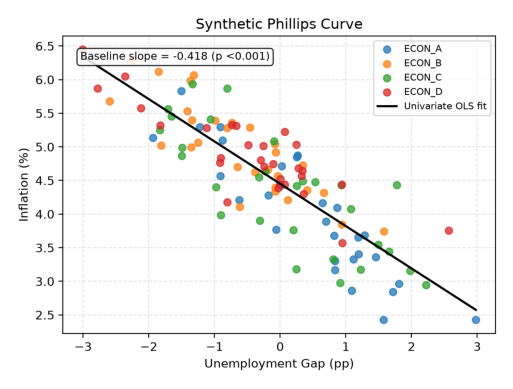

In [6]:
from matplotlib import image
from matplotlib import pyplot as plt

img = image.imread('reports/macro_demo/figures/phillips_scatter.png')
print(pd.DataFrame({'phillips_scatter.png': [img.shape[0], img.shape[1]]}, index=['height (px)', 'width (px)']))
plt.axis('off')
plt.imshow(img)

## Next steps

- [docs/quickstart.md](../docs/quickstart.md) - installation and the CLI run
- [docs/configuration.md](../docs/configuration.md) - YAML schema, includes, interpolation
- [docs/caching.md](../docs/caching.md) - fingerprints and invalidation reasons
- [docs/projects.md](../docs/projects.md) - the applied research pipelines
